# Study 15 — Aggregation-timescale sensitivity and 24 h regulatory-aligned onset

Two revision items, one pipeline, built on **study12's machinery** (multimodal `twin`, block-masked
outages, paired-bootstrap threshold sweep) so numbers are directly comparable to the paper's robustness result.

1. **Aggregation sweep** (detailed reviewer, Sec 2.2.4): re-run at 3 h / 6 h / 12 h, horizon fixed at ~24 h
   (H = round(24/STEP)), reporting discrimination and the marginalise-vs-forward-fill advantage by threshold.
2. **24 h regulatory-aligned onset** (short reviewer, point 1): redefine onset on the **24 h running mean**
   crossing the threshold and check the findings hold. Confirmatory evidence behind the argument-based defence.

The mechanism contrast is same-architecture, different missing-data policy: identical `twin`, marginalise
(mask -> NaN) vs impute (forward-fill), under **contiguous** block outages drawn from the real gap-length
distribution (recomputed per aggregation). cwd = `notebooks/`. Outputs -> `../outputs/study15_aggregation_24h/`.

**Runtime note:** `twin` is a pure-Python per-step filter; the 3 h case doubles series length. Expect several
minutes per aggregation. The user runs this notebook.


## Load Nordic PM2.5 + ERA5 (as study12)


In [1]:
import numpy as np, pandas as pd, math, matplotlib.pyplot as plt
from pathlib import Path
np.random.seed(0)
OUT=Path("../outputs/study15_aggregation_24h"); OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({"figure.dpi":130,"savefig.dpi":200,"font.size":11,"axes.grid":True,"grid.alpha":0.25,
                     "axes.spines.top":False,"axes.spines.right":False})
TAU=15.0
pm=pd.read_csv("../data/openaq_regional/regional_pm25.csv"); pm["datetime"]=pd.to_datetime(pm["datetime"],utc=True)
pm["name"]=pm.station.str.split("::").str[1]; pm=pm.dropna(subset=["value"]); pm=pm[(pm.value>=0)&(pm.value<1500)]
met=pd.read_csv("../data/era5/era5_regional.csv",usecols=["datetime","station","wind_speed","blh","t2m"])
met["datetime"]=pd.to_datetime(met["datetime"],utc=True); met=met.rename(columns={"station":"name"})
yrs=pm.groupby("station")["datetime"].agg(lambda s:(s.max()-s.min()).days/365.25); pm=pm[pm.station.isin(yrs[yrs>=2].index)].copy()
print("stations",pm.station.nunique())


/Users/sumiyasayeed/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
/Users/sumiyasayeed/anaconda3/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


stations 21


## Twin, metrics, logistic, paired bootstrap (verbatim from study12 / study3)


In [2]:
K=5; LEV=[i/(K-1) for i in range(K)]; SDL=[1.0+0.5*l for l in LEV]; LOGC=0.5*math.log(2*math.pi); LGC=[-LOGC-math.log(sd) for sd in SDL]
def lgv(z): return [LGC[k]-0.5*((z-2.0*LEV[k])/SDL[k])**2 for k in range(K)]
WPM,WW,WB,WT=1.0,0.5,0.5,0.4
def twin(zpm,zw,zb,zt,wpm=None,ww=None,wb=None,wt=None):
    wpm=WPM if wpm is None else wpm; ww=WW if ww is None else ww
    wb=WB if wb is None else wb;   wt=WT if wt is None else wt
    logb=[-3*k for k in range(K)]; m=max(logb); ss=sum(math.exp(x-m) for x in logb); logb=[x-m-math.log(ss) for x in logb]
    risk=np.empty(len(zpm)); ent=np.empty(len(zpm))
    for t in range(len(zpm)):
        mb=max(logb); b=[math.exp(x-mb) for x in logb]; sb=sum(b); b=[x/sb for x in b]
        el=sum(b[k]*LEV[k] for k in range(K)); up=0.25; pdn=0.05 if el>0.4 else 0.15; bp=[0.0]*K
        for k in range(K):
            u=up if k<K-1 else 0.0; d=pdn if k>0 else 0.0; bp[k]+=b[k]*(1-u-d)
            if k<K-1: bp[k+1]+=b[k]*u
            if k>0: bp[k-1]+=b[k]*d
        logbp=[math.log(x+1e-12) for x in bp]
        for zv,w,inv in [(zpm,wpm,1),(zw,ww,-1),(zb,wb,-1),(zt,wt,-1)]:
            if not math.isnan(zv[t]):
                lv=lgv(inv*zv[t]); logbp=[logbp[k]+w*lv[k] for k in range(K)]
        m2=max(logbp); s2=math.log(sum(math.exp(x-m2) for x in logbp)); logb=[x-m2-s2 for x in logbp]
        eb=[math.exp(x) for x in logb]; risk[t]=sum(eb[k]*LEV[k] for k in range(K)); ent[t]=-sum(p*math.log(p+1e-12) for p in eb)
    return risk,ent
def auc(s,y):
    s=np.asarray(s,float);y=np.asarray(y,int);pos,neg=(y==1),(y==0)
    if pos.sum()==0 or neg.sum()==0:return np.nan
    o=np.argsort(s);r=np.empty(len(s));r[o]=np.arange(1,len(s)+1)
    u,inv,c=np.unique(s,return_inverse=True,return_counts=True);sm=np.zeros(len(c));np.add.at(sm,inv,r);r=(sm/c)[inv]
    return float((r[pos].sum()-pos.sum()*(pos.sum()+1)/2)/(pos.sum()*neg.sum()))
def apr(s,y):
    s=np.asarray(s,float);y=np.asarray(y,int);o=np.argsort(-s);y=y[o];tp=np.cumsum(y);fp=np.cumsum(1-y);prec=tp/(tp+fp);rec=tp/max(y.sum(),1)
    return float(np.sum((rec-np.r_[0,rec[:-1]])*prec))
def sig(z): return 1/(1+np.exp(-np.clip(z,-30,30)))
def fitlog(X,y,ep=1500,lr=.25,l2=1.):
    X=np.asarray(X,float);mu=X.mean(0);sd=X.std(0)+1e-9;Xs=(X-mu)/sd;Xb=np.hstack([np.ones((len(Xs),1)),Xs]);w=np.zeros(Xb.shape[1])
    for _ in range(ep):
        p=sig(Xb@w);g=Xb.T@(p-y)/len(y);g[1:]+=l2/len(y)*w[1:];w-=lr*g
    return (w,mu,sd)
def predlog(m,X):
    w,mu,sd=m;Xs=(np.asarray(X,float)-mu)/sd;return sig(np.hstack([np.ones((len(Xs),1)),Xs])@w)
def paired_boot(sa,sb,y,n=2000,seed=1):
    sa=np.asarray(sa,float); sb=np.asarray(sb,float); y=np.asarray(y,int)
    rng=np.random.default_rng(seed); d=[]
    for _ in range(n):
        i=rng.integers(0,len(y),len(y)); yi=y[i]
        if not (0<yi.sum()<len(yi)): continue
        d.append(auc(sa[i],yi)-auc(sb[i],yi))
    d=np.array(d); lo,hi=np.percentile(d,[2.5,97.5])
    return float(auc(sa,y)-auc(sb,y)),float(lo),float(hi)
def verdict(lo,hi):
    if lo>0: return "marg better (sig)"
    if hi<0: return "marg WORSE (sig)"
    return "parity (spans 0)"


## Parameterised builders

`build_ST(STEP)` resamples PM2.5 + ERA5 at STEP h, z-scores on even-month stats, runs the twin once (clean),
and stores per-station `v` (STEP-mean) and `v24` (24 h running mean, window W=round(24/STEP)). It also returns the
observed contiguous gap-length distribution at that STEP for realistic block masking.


In [3]:
def build_ST(STEP):
    H=max(1,round(24/STEP)); W=max(1,round(24/STEP))
    ST={}
    for st,g in pm.groupby("station"):
        name=g["name"].iloc[0]
        s=g.set_index("datetime").value.resample(f"{STEP}h").mean()
        mg=met[met.name==name].set_index("datetime")[["wind_speed","blh","t2m"]].resample(f"{STEP}h").mean()
        idx=s.index; A=pd.DataFrame({"pm":s}).join(mg).reindex(idx); tm=(idx.month%2==0)
        def z(col,log=False):
            v=np.log1p(np.clip(A[col].to_numpy(),0,None)) if log else A[col].to_numpy()
            mu,sd=np.nanmean(v[tm]),np.nanstd(v[tm])+1e-9; return (v-mu)/sd
        zpm=z("pm",log=True); zw=z("wind_speed"); zb=z("blh"); zt=z("t2m")
        risk,ent=twin(zpm,zw,zb,zt)
        v=A["pm"].to_numpy()
        v24=pd.Series(v).rolling(W,min_periods=max(1,W//2)).mean().to_numpy()
        ST[st]=dict(zpm=zpm,zw=zw,zb=zb,zt=zt,v=v,v24=v24,tm=tm,
                    hr=idx.hour.to_numpy(),doy=idx.dayofyear.to_numpy(),risk=risk,risk_tr=np.r_[0,0,risk[2:]-risk[:-2]])
    # observed gap-length distribution at this STEP
    gaps=[]
    for st,d in ST.items():
        isnan=np.isnan(d["zpm"]); n=len(isnan); i=0
        while i<n:
            if isnan[i]:
                j=i
                while j<n and isnan[j]: j+=1
                gaps.append(j-i); i=j
            else: i+=1
    gaps=np.array(gaps) if gaps else np.arange(2,21)
    return ST,gaps,H,W

def block_mask(n,pdrop,rng,gaps):
    m=np.zeros(n,bool)
    if pdrop<=0: return m
    target=int(round(pdrop*n)); placed=0; guard=0
    while placed<target and guard<10*n:
        L=int(rng.choice(gaps)); L=max(1,min(L,n)); s=int(rng.integers(0,max(1,n-L)))
        new=(~m[s:s+L]).sum(); m[s:s+L]=True; placed+=new; guard+=L
    return m

def target_series(d,onset_mode): return d["v24"] if onset_mode=="mean24" else d["v"]


## Discrimination (clean data) at TAU=15, by onset mode


In [4]:
def discrimination(ST,H,onset_mode,tau=TAU):
    rows=[]
    for st,d in ST.items():
        tgt=target_series(d,onset_mode); v=d["v"]; tm=d["tm"]; zpm=d["zpm"]; risk=d["risk"]
        g2=lambda a:(a if not np.isnan(a) else 0.0)
        for t in range(2,len(v)-H):
            if np.isnan(tgt[t]) or tgt[t]>=tau: continue
            fut=tgt[t+1:t+1+H]
            if np.all(np.isnan(fut)): continue
            rows.append(dict(split=("train" if tm[t] else "test"),label=int(np.nanmax(fut)>=tau),
                cur=g2(zpm[t]),trend=g2(zpm[t]-zpm[t-2]),risk=risk[t],risk_tr=g2(risk[t]-risk[t-2])))
    S=pd.DataFrame(rows); tr,te=S[S.split=="train"],S[S.split=="test"]
    res={"B1 current level":te.cur.values,
         "B2 logistic(level,trend)":predlog(fitlog(tr[["cur","trend"]].values,tr.label.values),te[["cur","trend"]].values),
         "P1 twin risk (no labels)":te.risk.values,
         "P2 logistic twin":predlog(fitlog(tr[["risk","risk_tr"]].values,tr.label.values),te[["risk","risk_tr"]].values)}
    out=[(k,auc(v,te.label.values),apr(v,te.label.values)) for k,v in res.items()]
    return pd.DataFrame(out,columns=["model","AUROC","AUPRC"]).set_index("model"), S.label.mean(), len(te)


## Mechanism contrast: marginalise vs forward-fill, by threshold (paired bootstrap)

Same twin, two missing-data policies, under block outages. Twin risk depends only on z (not on tau), so one twin
pass per (loss, policy) is relabelled at each threshold. Test partition only.


In [5]:
def risk_pair(ST,gaps,pdrop,seed):
    rng=np.random.default_rng(seed); out={}
    for st,d in ST.items():
        zpm=d["zpm"]; n=len(zpm); miss=block_mask(n,pdrop,rng,gaps)
        zff=zpm.copy()
        for i in range(n):
            if miss[i]: zff[i]=zff[i-1] if i>0 else zff[i]
        zn=zpm.copy(); zn[miss]=np.nan
        r_ff,_=twin(zff,d["zw"],d["zb"],d["zt"]); r_mg,_=twin(zn,d["zw"],d["zb"],d["zt"])
        out[st]=(r_ff,r_mg)
    return out

def mech_by_threshold(ST,gaps,H,onset_mode,taus=(10.,15.,25.,35.),losses=(0.0,0.30,0.70,0.85)):
    rows=[]
    for p in losses:
        pair=risk_pair(ST,gaps,p,seed=0)
        for tau in taus:
            A=[];B=[];Y=[]
            for st,d in ST.items():
                r_ff,r_mg=pair[st]; tgt=target_series(d,onset_mode); tm=d["tm"]
                for t in range(2,len(tgt)-H):
                    if np.isnan(tgt[t]) or tgt[t]>=tau or tm[t]: continue
                    fut=tgt[t+1:t+1+H]
                    if np.all(np.isnan(fut)): continue
                    A.append(r_ff[t]); B.append(r_mg[t]); Y.append(int(np.nanmax(fut)>=tau))
            Y=np.array(Y,int)
            if Y.sum()<30 or Y.sum()==len(Y):
                print(f"  tau={tau:>4.0f} loss={p:>4.0%}  too few onsets (n={Y.sum()}) - skipped"); continue
            A=np.array(A,float); B=np.array(B,float)
            diff,lo,hi=paired_boot(B,A,Y)
            rows.append(dict(onset=onset_mode,tau=tau,loss=p,base_rate=float(Y.mean()),n_onset=int(Y.sum()),
                             ff=auc(A,Y),marg=auc(B,Y),diff=diff,lo95=lo,hi95=hi))
            print(f"  tau={tau:>4.0f} loss={p:>4.0%} | base {Y.mean():.4f} n {Y.sum():>5} | ff {auc(A,Y):.3f} marg {auc(B,Y):.3f} | {diff:+.4f} [{lo:+.4f},{hi:+.4f}] {verdict(lo,hi)}")
    return pd.DataFrame(rows)


## 1. Aggregation sweep (3 h / 6 h / 12 h), step onset


In [6]:
STEPS=[3,6,12]
disc_rows=[]; mech_all=[]
for STEP in STEPS:
    ST,gaps,H,W=build_ST(STEP)
    d,prev,nte=discrimination(ST,H,"step")
    d=d.assign(aggregation=f"{STEP}h",onset="step",prevalence=prev,n_test=nte); disc_rows.append(d.reset_index())
    print(f"\n### STEP={STEP}h  H={H}  24h-window W={W} | prevalence {prev:.3f} | test {nte} ###")
    print(d[["AUROC","AUPRC"]].round(3).to_string())
    print("marginalise vs forward-fill by threshold:")
    m=mech_by_threshold(ST,gaps,H,"step"); m["aggregation"]=f"{STEP}h"; mech_all.append(m)
agg_disc=pd.concat(disc_rows,ignore_index=True); agg_disc.to_csv(OUT/"s15_aggregation_discrimination.csv",index=False)
agg_mech=pd.concat(mech_all,ignore_index=True); agg_mech.to_csv(OUT/"s15_aggregation_mechanism.csv",index=False)
print("\nsaved aggregation CSVs")


/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_69338/693803628.py:17: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  hr=idx.hour.to_numpy(),doy=idx.dayofyear.to_numpy(),risk=risk,risk_tr=np.r_[0,0,risk[2:]-risk[:-2]])
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_69338/693803628.py:17: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  hr=idx.hour.to_numpy(),doy=idx.dayofyear.to_numpy(),risk=risk,risk_tr=np.r_[0,0,risk[2:]-risk[:-2]])
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_69338/693803628.py:17: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  hr=idx.hour.to_numpy(),doy=idx.dayofyear.to_numpy(),risk=risk,risk_tr=np.r_[0,0,risk[2:]-risk[:-2]])
/var/folders/hs/v3rv3f714391byj_w2dh_q98000


### STEP=3h  H=8  24h-window W=8 | prevalence 0.103 | test 93759 ###
                          AUROC  AUPRC
model                                 
B1 current level          0.732  0.236
B2 logistic(level,trend)  0.748  0.249
P1 twin risk (no labels)  0.768  0.293
P2 logistic twin          0.767  0.293
marginalise vs forward-fill by threshold:
  tau=  10 loss=  0% | base 0.2176 n 18770 | ff 0.705 marg 0.705 | +0.0000 [+0.0000,+0.0000] parity (spans 0)
  tau=  15 loss=  0% | base 0.0950 n  8911 | ff 0.768 marg 0.768 | +0.0000 [+0.0000,+0.0000] parity (spans 0)
  tau=  25 loss=  0% | base 0.0334 n  3253 | ff 0.842 marg 0.842 | +0.0000 [+0.0000,+0.0000] parity (spans 0)
  tau=  35 loss=  0% | base 0.0146 n  1429 | ff 0.870 marg 0.870 | +0.0000 [+0.0000,+0.0000] parity (spans 0)
  tau=  10 loss= 30% | base 0.2176 n 18770 | ff 0.683 marg 0.668 | -0.0144 [-0.0168,-0.0123] marg WORSE (sig)
  tau=  15 loss= 30% | base 0.0950 n  8911 | ff 0.746 marg 0.731 | -0.0143 [-0.0170,-0.0116] marg WORSE 

/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_69338/693803628.py:17: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  hr=idx.hour.to_numpy(),doy=idx.dayofyear.to_numpy(),risk=risk,risk_tr=np.r_[0,0,risk[2:]-risk[:-2]])
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_69338/693803628.py:17: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  hr=idx.hour.to_numpy(),doy=idx.dayofyear.to_numpy(),risk=risk,risk_tr=np.r_[0,0,risk[2:]-risk[:-2]])
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_69338/693803628.py:17: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  hr=idx.hour.to_numpy(),doy=idx.dayofyear.to_numpy(),risk=risk,risk_tr=np.r_[0,0,risk[2:]-risk[:-2]])
/var/folders/hs/v3rv3f714391byj_w2dh_q98000


### STEP=6h  H=4  24h-window W=4 | prevalence 0.073 | test 48209 ###
                          AUROC  AUPRC
model                                 
B1 current level          0.759  0.200
B2 logistic(level,trend)  0.773  0.220
P1 twin risk (no labels)  0.794  0.254
P2 logistic twin          0.791  0.257
marginalise vs forward-fill by threshold:
  tau=  10 loss=  0% | base 0.1601 n  7126 | ff 0.719 marg 0.719 | +0.0000 [+0.0000,+0.0000] parity (spans 0)
  tau=  15 loss=  0% | base 0.0698 n  3364 | ff 0.794 marg 0.794 | +0.0000 [+0.0000,+0.0000] parity (spans 0)
  tau=  25 loss=  0% | base 0.0231 n  1152 | ff 0.867 marg 0.867 | +0.0000 [+0.0000,+0.0000] parity (spans 0)
  tau=  35 loss=  0% | base 0.0105 n   529 | ff 0.877 marg 0.877 | +0.0000 [+0.0000,+0.0000] parity (spans 0)
  tau=  10 loss= 30% | base 0.1601 n  7126 | ff 0.692 marg 0.689 | -0.0025 [-0.0056,+0.0005] parity (spans 0)
  tau=  15 loss= 30% | base 0.0698 n  3364 | ff 0.757 marg 0.764 | +0.0070 [+0.0032,+0.0108] marg better

/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_69338/693803628.py:17: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  hr=idx.hour.to_numpy(),doy=idx.dayofyear.to_numpy(),risk=risk,risk_tr=np.r_[0,0,risk[2:]-risk[:-2]])
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_69338/693803628.py:17: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  hr=idx.hour.to_numpy(),doy=idx.dayofyear.to_numpy(),risk=risk,risk_tr=np.r_[0,0,risk[2:]-risk[:-2]])
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_69338/693803628.py:17: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  hr=idx.hour.to_numpy(),doy=idx.dayofyear.to_numpy(),risk=risk,risk_tr=np.r_[0,0,risk[2:]-risk[:-2]])
/var/folders/hs/v3rv3f714391byj_w2dh_q98000


### STEP=12h  H=2  24h-window W=2 | prevalence 0.046 | test 24576 ###
                          AUROC  AUPRC
model                                 
B1 current level          0.798  0.147
B2 logistic(level,trend)  0.800  0.149
P1 twin risk (no labels)  0.813  0.188
P2 logistic twin          0.813  0.198
marginalise vs forward-fill by threshold:
  tau=  10 loss=  0% | base 0.1100 n  2498 | ff 0.732 marg 0.732 | +0.0000 [+0.0000,+0.0000] parity (spans 0)
  tau=  15 loss=  0% | base 0.0436 n  1072 | ff 0.813 marg 0.813 | +0.0000 [+0.0000,+0.0000] parity (spans 0)
  tau=  25 loss=  0% | base 0.0121 n   308 | ff 0.879 marg 0.879 | +0.0000 [+0.0000,+0.0000] parity (spans 0)
  tau=  35 loss=  0% | base 0.0048 n   124 | ff 0.887 marg 0.887 | +0.0000 [+0.0000,+0.0000] parity (spans 0)
  tau=  10 loss= 30% | base 0.1100 n  2498 | ff 0.708 marg 0.698 | -0.0106 [-0.0161,-0.0053] marg WORSE (sig)
  tau=  15 loss= 30% | base 0.0436 n  1072 | ff 0.780 marg 0.783 | +0.0024 [-0.0041,+0.0093] parity (sp

## 2. 24 h regulatory-aligned onset (STEP=6) vs 6 h step onset


In [7]:
ST6,gaps6,H6,W6=build_ST(6)
d_step,prev_s,nte_s=discrimination(ST6,H6,"step")
d_m24 ,prev_m,nte_m=discrimination(ST6,H6,"mean24")
print("6h-step  onset: prevalence %.3f test %d"%(prev_s,nte_s)); print(d_step.round(3).to_string())
print("\n24h-mean onset: prevalence %.3f test %d"%(prev_m,nte_m)); print(d_m24.round(3).to_string())
pd.concat({"6h_step":d_step,"24h_mean":d_m24},names=["onset"]).reset_index().to_csv(OUT/"s15_onset_discrimination.csv",index=False)

print("\n--- mechanism by threshold: 6h-step ---");  m_step=mech_by_threshold(ST6,gaps6,H6,"step")
print("\n--- mechanism by threshold: 24h-mean ---"); m_m24 =mech_by_threshold(ST6,gaps6,H6,"mean24")
pd.concat([m_step,m_m24],ignore_index=True).to_csv(OUT/"s15_onset_mechanism.csv",index=False)
print("\nsaved 24h-onset CSVs")


/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_69338/693803628.py:17: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  hr=idx.hour.to_numpy(),doy=idx.dayofyear.to_numpy(),risk=risk,risk_tr=np.r_[0,0,risk[2:]-risk[:-2]])
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_69338/693803628.py:17: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  hr=idx.hour.to_numpy(),doy=idx.dayofyear.to_numpy(),risk=risk,risk_tr=np.r_[0,0,risk[2:]-risk[:-2]])
/var/folders/hs/v3rv3f714391byj_w2dh_q980000gn/T/ipykernel_69338/693803628.py:17: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  hr=idx.hour.to_numpy(),doy=idx.dayofyear.to_numpy(),risk=risk,risk_tr=np.r_[0,0,risk[2:]-risk[:-2]])
/var/folders/hs/v3rv3f714391byj_w2dh_q98000

6h-step  onset: prevalence 0.073 test 48209
                          AUROC  AUPRC
model                                 
B1 current level          0.759  0.200
B2 logistic(level,trend)  0.773  0.220
P1 twin risk (no labels)  0.794  0.254
P2 logistic twin          0.791  0.257

24h-mean onset: prevalence 0.028 test 50971
                          AUROC  AUPRC
model                                 
B1 current level          0.861  0.235
B2 logistic(level,trend)  0.866  0.240
P1 twin risk (no labels)  0.857  0.154
P2 logistic twin          0.846  0.190

--- mechanism by threshold: 6h-step ---
  tau=  10 loss=  0% | base 0.1601 n  7126 | ff 0.719 marg 0.719 | +0.0000 [+0.0000,+0.0000] parity (spans 0)
  tau=  15 loss=  0% | base 0.0698 n  3364 | ff 0.794 marg 0.794 | +0.0000 [+0.0000,+0.0000] parity (spans 0)
  tau=  25 loss=  0% | base 0.0231 n  1152 | ff 0.867 marg 0.867 | +0.0000 [+0.0000,+0.0000] parity (spans 0)
  tau=  35 loss=  0% | base 0.0105 n   529 | ff 0.877 marg 0.877 | +0.00

## Figures


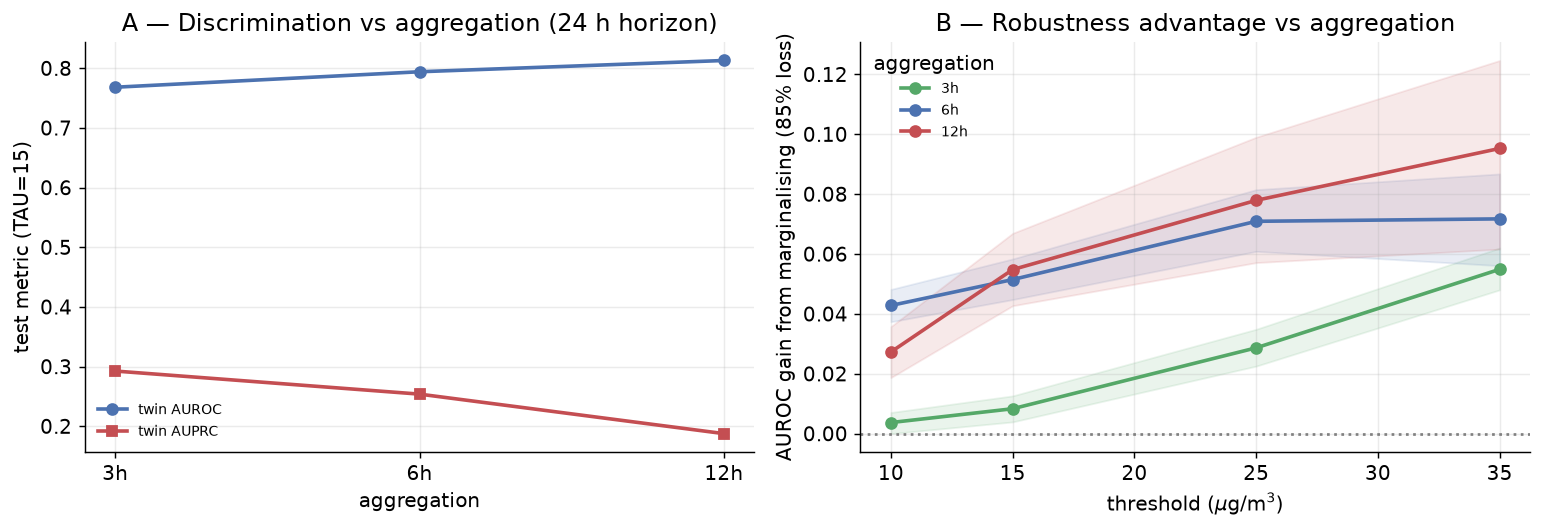

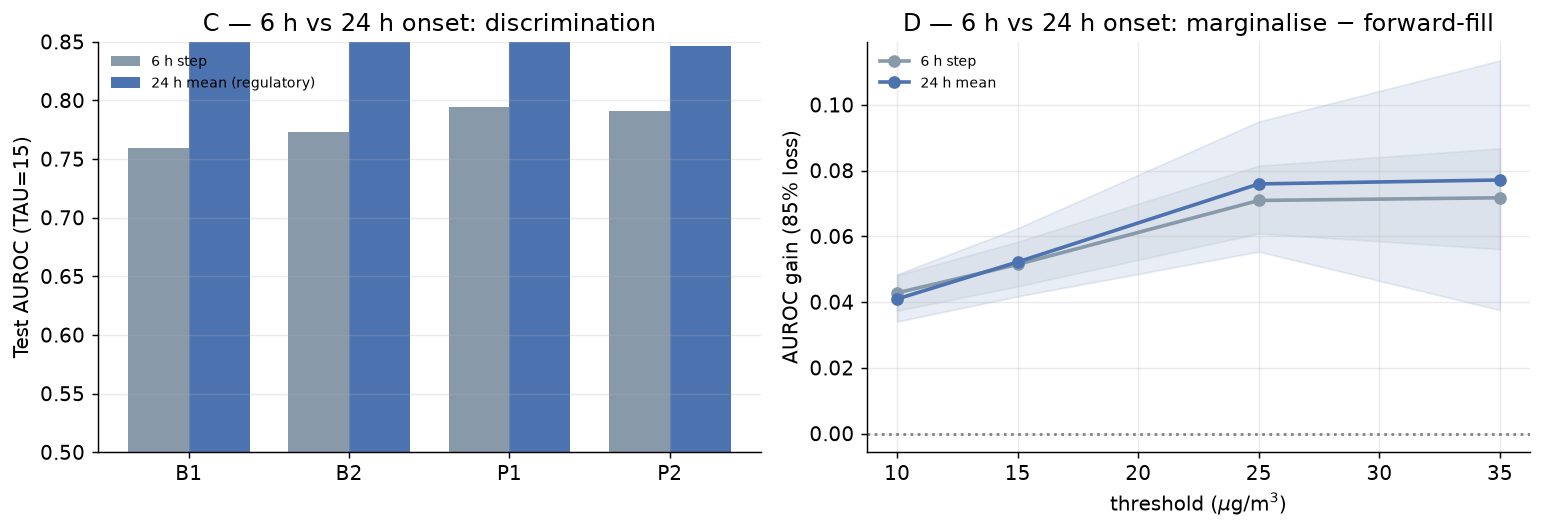

saved figures to ../outputs/study15_aggregation_24h


In [8]:
# A: twin AUROC across aggregation; B: marg-minus-ff advantage at 85% loss across aggregation and threshold
fig,ax=plt.subplots(1,2,figsize=(12,4.2))
tw=agg_disc[agg_disc.model=="P1 twin risk (no labels)"]
ax[0].plot(tw.aggregation,tw.AUROC,"-o",color="#4C72B0",lw=2,label="twin AUROC")
ax[0].plot(tw.aggregation,tw.AUPRC,"-s",color="#C44E52",lw=2,label="twin AUPRC")
ax[0].set_xlabel("aggregation"); ax[0].set_ylabel("test metric (TAU=15)")
ax[0].set_title("A — Discrimination vs aggregation (24 h horizon)"); ax[0].legend(frameon=False,fontsize=8)
hi=agg_mech[agg_mech.loss==0.85]
for ag,c in zip([f"{s}h" for s in STEPS],["#55A868","#4C72B0","#C44E52"]):
    g=hi[hi.aggregation==ag].sort_values("tau")
    ax[1].plot(g.tau,g["diff"],"-o",color=c,lw=2,label=ag)
    ax[1].fill_between(g.tau,g.lo95,g.hi95,color=c,alpha=.12)
ax[1].axhline(0,ls=":",c="grey"); ax[1].set_xlabel(r"threshold ($\mu$g/m$^3$)")
ax[1].set_ylabel("AUROC gain from marginalising (85% loss)")
ax[1].set_title("B — Robustness advantage vs aggregation"); ax[1].legend(title="aggregation",frameon=False,fontsize=8)
plt.tight_layout(); plt.savefig(OUT/"s15_fig1_aggregation.png",bbox_inches="tight"); plt.show()

# C/D: 6h vs 24h onset — discrimination and mechanism-by-threshold at 85% loss
mech=pd.read_csv(OUT/"s15_onset_mechanism.csv")
fig,ax=plt.subplots(1,2,figsize=(12,4.2))
mods=d_step.index.tolist(); x=np.arange(len(mods)); w=.38
ax[0].bar(x-w/2,d_step.AUROC,w,label="6 h step",color="#8899AA")
ax[0].bar(x+w/2,d_m24.AUROC,w,label="24 h mean (regulatory)",color="#4C72B0")
ax[0].set_xticks(x); ax[0].set_xticklabels([m.split()[0] for m in mods]); ax[0].set_ylim(0.5,0.85)
ax[0].set_ylabel("Test AUROC (TAU=15)"); ax[0].set_title("C — 6 h vs 24 h onset: discrimination"); ax[0].legend(frameon=False,fontsize=8)
for mode,c in [("step","#8899AA"),("mean24","#4C72B0")]:
    g=mech[(mech.onset==mode)&(mech.loss==0.85)].sort_values("tau")
    ax[1].plot(g.tau,g["diff"],"-o",color=c,lw=2,label=("6 h step" if mode=="step" else "24 h mean"))
    ax[1].fill_between(g.tau,g.lo95,g.hi95,color=c,alpha=.12)
ax[1].axhline(0,ls=":",c="grey"); ax[1].set_xlabel(r"threshold ($\mu$g/m$^3$)"); ax[1].set_ylabel("AUROC gain (85% loss)")
ax[1].set_title("D — 6 h vs 24 h onset: marginalise − forward-fill"); ax[1].legend(frameon=False,fontsize=8)
plt.tight_layout(); plt.savefig(OUT/"s15_fig2_onset_6h_vs_24h.png",bbox_inches="tight"); plt.show()
print("saved figures to",OUT)


## Reading this for the reply

- **Aggregation (Sec 2.2.4):** if twin AUROC/AUPRC (A) and the threshold-resolved advantage (B) are stable across
  3/6/12 h, the 6 h choice is not load-bearing; justify it as a noise-vs-lead-time compromise.
- **24 h onset (point 1):** compare panels C and D against the paper's 6 h result. If the advantage still grows with
  threshold under the 24 h-mean definition, state that the marginalisation finding holds on the regulatory metric and
  cite these numbers behind Edison's argument in Threats to Validity. Report honestly if it weakens.
- Sanity check: at STEP=6, step onset should reproduce study12 (e.g. ~ +0.05 at 15 ug / 85% loss, growing to ~+0.07 at 35 ug).
